# Step 11: steps 9 + 10 fixed and combined (GPU T4, ~1-1.5 h)
One notebook that keeps what worked in steps 9 and 10 and fixes what did not. Every fix is scored against the
thing it replaces, on the same patients, so each one can be defended on its own.

| problem in steps 9 / 10 | fix here | evidence |
|---|---|---|
| intensities divided by one number per patient: coil bias field and scanner histogram differences stay | **N4 bias-field correction + Nyul piecewise-linear histogram standardisation** (one mapping per patient, from the pre-contrast image, applied to all 3 phases so the enhancement is kept; standard scale learned on train only) | most robust normalisation for breast-MRI radiomics in a pCR study (arXiv 2406.01736) |
| tumour = raw PE >= 0.7 threshold in the box: specks of parenchyma / vessels | **one cleaned mask rule for every cohort** (largest components, holes filled); Dice vs the I-SPY masks reported | `src/vitonly/roi.py` |
| only the tumour was described | **peritumoral rings 0-3 / 3-6 / 6-9 / 9-12 mm** | Braman 2017: intra + peritumoral, AUC 0.74 on an independent test set |
| tumour treated as one homogeneous blob | **habitats**: kinetic sub-regions (curve type x enhancement), fractions, entropy, rim vs core | DCE habitat imaging, two-centre externally validated pCR study |
| ViT saw 8 central slices, plain mean | **every tumour slice**, weighted by its tumour area, `sub` input (best probe setting) | step 10 probe; tumour edge carries the peritumoral signal |
| ViT + hand-crafted fusion never ran (step-9 output not attached) | **both in one run**, ViT reduced to 32 PCA components inside each fold | |
| one 5-fold CV + 177 val patients (CI +-0.08) | **5 x repeated 5-fold CV, C tuned by an inner CV, out-of-fold AUC on all ~1,100 train patients**, per subtype and per cohort | `src/vitonly/rcv.py` |
| image never added to subtype | every set also scored **+subtype** and **per subtype** (one model per HR/HER2 subtype) | Braman 2017; I-SPY2 subtype-specific models |

Kaggle setup: Accelerator **GPU T4 x2** (the radiomics part is CPU, the ViT part needs the GPU), Internet **ON**.
**+ Add Input**:
- the caches (the best one attached per cohort is used and printed): **`mnj-cache2-ispy1/-ispy2/-duke`** (raw,
  step 2: nothing clipped) if you have them, else `mnj-cache-v2` or `mnj-cache-ispy1/-ispy2/-duke` (uint8, clipped:
  the code works, but the brightest enhancement is lost);
- the code: the **`mnj-code-vaib` Dataset, NEW version** (the zip made on 2026-11-04 or later has the steps 11-13
  code; the setup cell stops with a clear message if the attached code is older).

Run with `DEBUG = True` first (a few minutes, 40 patients per split) to check the notebook, then `DEBUG = False`
with **Save Version -> Save & Run All (Commit)**. Every step prints a timestamped `[...]` line. Results: Output tab,
`results/<PERSON>/<step>/`. Background and rationale: `docs/vaib/STEPS_11_13.md`.
Run order: steps 11 and 12 are independent (run them in parallel); step 13 uses both outputs.

In [1]:
# ==== PARAMETERS (edit these) ====
REPO = "AkulaReddy/MRI_chemo_response"
GIT_TAG = "vaib"           # branch (or tag) to clone
PERSON = ""               # optional: "A", "B" or "C" -> results/<PERSON>/ (empty -> results/vaib/)
STEP = "step11"
PREFER = "v2"                # cache format when several are attached: v2 = raw mnj-cache2-*, v1 = uint8
USE_N4 = True                # N4 bias-field correction before Nyul (needs SimpleITK, installed below)
RUN_VIT = True               # frozen DINOv2 on every tumour slice (GPU)
BACKBONE = "dinov2_b"
VIT_NORM = "sub"             # log pre / wash-in / wash-out channels: the best CV setting of the 74-setting probe
MAX_SLICES = 32
MODES = ["image", "+subtype", "per_subtype"]
COMBAT = True                # also score every set with ComBat (batch = acquisition protocol, fitted inside each fold)
REPEATS = 5                  # repeated 5-fold CV (DEBUG uses 2)
JOBS = 4                     # CPU processes
EXTRA_PIP = ["SimpleITK"]
TIME_BUDGET_H = 11.0
DEBUG = False                # True: 40 patients per split, 2 CV repeats: a few minutes, to check the notebook
PUSH_RESULTS = False
NOTEBOOK_NAME = "step11"

In [2]:
# ==== SETUP (do not edit): get the repo code, install requirements ====
import base64, glob, json, os, shutil, subprocess, sys, zipfile
if PERSON not in ("A", "B", "C"):           # only names the results folder
    PERSON = "vaib"
    print('PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)')
NEEDS = "src/vitonly/rcv.py"               # the steps 11-13 code (in the mnj-code-vaib zip made on 2026-11-04 or later)
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as e:
    print("no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached):",
          type(e).__name__)

def git(*args, cwd="/tmp/repo"):
    """git with the token as a one-off header (never stored in .git/config or the output)."""
    if not _tok:
        raise RuntimeError("no GITHUB_TOKEN secret: git push/pull is not available")
    hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={hdr}", *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(_tok, "***")
    if r.returncode:
        raise RuntimeError(f"git {args[0]} failed:\n{out}")
    return out

def _find_code():
    """An attached code Dataset that already has the steps 11-13 code (an unpacked folder or the uploaded zip)."""
    hits = [h for d in range(1, 8) for h in glob.glob("/kaggle/input/" + "*/" * d + NEEDS)]
    if not hits:
        for z in [z for d in range(1, 6) for z in glob.glob("/kaggle/input/" + "*/" * d + "mnj-code-vaib*.zip")]:
            zipfile.ZipFile(z).extractall("/tmp/code_zip")
        hits = glob.glob("/tmp/code_zip/**/" + NEEDS, recursive=True)
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

shutil.rmtree("/tmp/repo", ignore_errors=True)
code_root = _find_code()
if code_root:                               # 1) the attached code Dataset with the new code wins
    shutil.copytree(code_root, "/tmp/repo")
    print("code: attached Dataset", code_root)
elif _tok:                                  # 2) or clone the branch from GitHub
    git("clone", "--quiet", "--depth", "1", "--branch", GIT_TAG, f"https://github.com/{REPO}.git", "/tmp/repo", cwd="/tmp")
    print("code: GitHub", REPO, GIT_TAG, git("log", "-1", "--format=%h %s"))
    if not os.path.exists(f"/tmp/repo/{NEEDS}"):
        raise SystemExit(f"branch {GIT_TAG} has no steps 11-13 code ({NEEDS}). Attach the NEW mnj-code-vaib zip "
                         "(+ Add Input -> Your Datasets -> mnj-code-vaib, latest version), or set GIT_TAG to a branch with it.")
else:
    print("attached inputs:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") <= 5:
            print("  ", root, dirs[:6], files[:4])
        else:
            dirs[:] = []
    raise SystemExit(
        "\nThe notebook can't find the steps 11-13 code. Upload the new mnj-code-vaib.zip as a NEW VERSION of the\n"
        "mnj-code-vaib Dataset, then + Add Input -> Your Datasets -> mnj-code-vaib (latest version) and Run All again.")
os.chdir("/tmp/repo")
sys.path.insert(0, "/tmp/repo")         # so `from src...` works in this kernel
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-kaggle.txt"], check=True)
for pkg in EXTRA_PIP:                   # optional extras: a failed install is reported, never fatal
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    print(f"pip install {pkg}:", "ok" if r.returncode == 0 else "FAILED (the step that needs it is skipped)\n" + r.stderr[-500:])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)
no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached): BackendError
code: attached Dataset /kaggle/input/datasets/a15chvaibhav/mnj-code-vaib/MRI_chemo_response
pip install SimpleITK: ok
torch 2.11.0+cu130 | GPU: Tesla T4


In [3]:
# ==== HELPERS (do not edit): training runs, prediction files, comparisons ====
import glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import evaluation as ev, stats
from src.train import find_caches
from src.data.metadata import patient_table
COH = ["ispy1", "ispy2", "duke"]
OUT = f"/kaggle/working/results/{PERSON}/{STEP}"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
RUNS_JSON = {}
pd.set_option("display.width", 250, "display.max_columns", 40)

def budget_left():
    return TIME_BUDGET_H - (time.time() - T0) / 3600

def say(msg):
    """Timestamped progress line (elapsed and remaining budget), flushed so it shows in the Kaggle log at once."""
    el = (time.time() - T0) / 3600
    print(f"[{time.strftime('%H:%M:%S')} | {el:.2f} h elapsed, {budget_left():.2f} h left] {msg}", flush=True)

def run_cmd(cmd):
    """Run a training subprocess and stream its output line by line into this notebook (subprocess.run alone
    shows nothing until it ends, and the child's stdout is block-buffered without PYTHONUNBUFFERED)."""
    print("\n" + " ".join(cmd), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait():
        raise subprocess.CalledProcessError(p.returncode, cmd)
    say(f"finished in {(time.time() - t) / 60:.1f} min")

def check_caches(version):
    caches = find_caches(["/kaggle/input", "/kaggle/working"])
    info = {c: json.load(open(f"{d}/cache_meta.json")).get("builder_version", 1) for c, d in caches.items()}
    print("caches:", {c: f"builder v{v}: {caches[c]}" for c, v in info.items()})
    if version is not None:
        bad = {c: v for c, v in info.items() if v != version}
        assert not bad and len(info) == 3, (f"need cache builder v{version} for all 3 cohorts (attach mnj-cache-v2); "
                                            f"found {info}")
    return caches

def _copy(d, label):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    for f in ("val_preds.csv", "metrics.json", "log.csv", "config_resolved.yaml", "export_preds.csv",
              "train_preds.csv", "encoder.json"):
        if os.path.exists(f"{d}/{f}"):
            shutil.copy(f"{d}/{f}", f"{OUT}/{label}/{f}")

def train(config, seed, sets=(), label=None, cohorts=None):
    """One src.train run (B3 / F2 ...) -> (run_dir, metrics). Its small files are copied to OUT/<label>/."""
    cmd = [sys.executable, "-m", "src.train", "--config", config, "--seed", str(seed), "--out", "/kaggle/working/runs"]
    if CACHE_VERSION is not None: cmd += ["--cache-version", str(CACHE_VERSION)]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d, json.load(open(f"{d}/metrics.json"))

def finetune(config, seed, sets=(), label=None, cohorts=None):
    """One src.vitonly.finetune run (our pipeline: ViT-only vo_base / fusion vo_fusion) -> run_dir."""
    cmd = [sys.executable, "-m", "src.vitonly.finetune", "--config", config, "--seed", str(seed),
           "--cache-root", "/kaggle/input", "/kaggle/working", "--out", "/kaggle/working/runs"]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d

def note_runs(key, dirs):
    """label -> run folder names, in OUT/runs.json: step 8 uses it to find the checkpoints."""
    RUNS_JSON[key] = [os.path.basename(d) for d in dirs]
    json.dump(RUNS_JSON, open(f"{OUT}/runs.json", "w"), indent=1)

def preds_of(dirs):
    fr = [ev.load_preds(f"{d}/val_preds.csv") for d in dirs]
    return fr[0] if len(fr) == 1 else ev.ensemble(fr)

def save_preds(label, df):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    df.to_csv(f"{OUT}/{label}/val_preds.csv", index=False)
    return df

def repo_preds(pattern):
    hits = sorted(glob.glob(f"results/*/{pattern}/val_preds.csv"))
    return preds_of([os.path.dirname(h) for h in hits]) if hits else None

def train_auc(d):
    """AUC on the training patients from export_preds.csv (B3 exports after training): the overfitting gap."""
    f = f"{d}/export_preds.csv"
    if not os.path.exists(f): return np.nan
    e = pd.read_csv(f); e = e[e.split == "train"]
    return stats.auc(e.label, e.prob)

def vo_train_auc(d):
    """Training-set AUC of a src.vitonly run (metrics.json): the overfitting gap."""
    return json.load(open(f"{d}/metrics.json"))["val"].get("train_auc", np.nan)

def compare(preds, ref):
    """One row per model on the patients all models share: AUC (DeLong CI), AUPRC, Brier, ECE, the 90%-spec
    operating point (threshold chosen on these same val patients: optimistic), and the paired DeLong test
    and paired bootstrap of the AUC difference vs `ref`."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    rows = []
    for k, d in preds.items():
        r = {"model": k, **ev.summary_row(d.label, d.prob)}
        if k != ref and ref in preds:
            y = preds[ref].label
            dl = ev.delong(y, preds[ref].prob, d.prob)
            pb = stats.paired_bootstrap_auc_diff(y, preds[ref].prob, d.prob)
            r.update(diff_vs_ref=dl["diff"], delong_ci_lo=dl["ci"][0], delong_ci_hi=dl["ci"][1], delong_p=dl["p"],
                     boot_p=pb["p"])
        rows.append(r)
    cols = ["model", "n", "pcr", "auc", "ci_lo", "ci_hi", "auprc", "brier", "ece", "sens@90spec", "ppv@90spec",
            "npv@90spec", "diff_vs_ref", "delong_ci_lo", "delong_ci_hi", "delong_p", "boot_p"]
    t = pd.DataFrame(rows)
    return t[[c for c in cols if c in t]]

def subtype_wide(preds, by="subtype"):
    """AUC (95% CI) per subtype (or cohort) for every model, all on the same patients; n / pCR+ per group."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    tabs = {k: ev.subgroup_table(d, by).set_index(by) for k, d in preds.items()}
    first = next(iter(tabs.values()))
    out = pd.DataFrame({"n": first.n.astype(int), "pCR+": first.pcr.astype(int)})
    for k, t in tabs.items():
        out[k] = [f"{a:.3f} ({lo:.2f}-{hi:.2f})" if a == a else "n/a (one class)"
                  for a, lo, hi in zip(t.auc, t.ci_lo, t.ci_hi)]
    return out

B1_VAL = repo_preds("b1_lr_s0_*")                       # clinical + tumour size, logistic regression (val 0.653)
B0_VAL = repo_preds("b0_lr_s0_*")                       # clinical only (val 0.639)
AKULA_B3_V2 = repo_preds("b3_vit_s0_1019-0302_*")       # Akula's B3 on cache v2 (val 0.559)
B3_V1 = repo_preds("b3_vit_s0_1009-1616_*")             # B3 on the old cache (val 0.530)
F2_V1 = repo_preds("f2_attn_s0_1009-1605_*")            # fusion on the old cache (val 0.690)
print("reference predictions from the repo:", {k: v is not None for k, v in
      dict(B1=B1_VAL, B0=B0_VAL, B3_v2_Akula=AKULA_B3_V2, B3_v1=B3_V1, F2_v1=F2_V1).items()})

reference predictions from the repo: {'B1': True, 'B0': True, 'B3_v2_Akula': True, 'B3_v1': True, 'F2_v1': True}


In [4]:
# ==== which cache is used for each cohort ====
from src.vitonly.slabs import find_caches as vo_find_caches, cache_label
VO_CACHES = vo_find_caches(["/kaggle/input", "/kaggle/working"], PREFER)
say(f"caches found: {len(VO_CACHES)} cohorts")
for c in COH:
    print(f"  {c:6s}", f"{cache_label(VO_CACHES[c])}  {VO_CACHES[c]}" if c in VO_CACHES else "MISSING -> left out", flush=True)
if not VO_CACHES:
    raise SystemExit("no cache attached: + Add Input -> mnj-cache2-* / mnj-cache-v2 / mnj-cache-*")
if any(cache_label(d).startswith("v1") for d in VO_CACHES.values()):
    print("NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. "
          "Raw mnj-cache2-* caches (step 2) are exact.", flush=True)

[08:35:58 | 0.00 h elapsed, 11.00 h left] caches found: 3 cohorts
  ispy1  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
  ispy2  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
  duke   v1 uint8 builder 1  /kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke
NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. Raw mnj-cache2-* caches (step 2) are exact.


## 1. Radiomics 2.0 (CPU, ~30-45 min)
Pass 1: N4 bias field (estimated on the pre-contrast slab) and the Nyul landmarks of every patient; the standard
scale is the mean over the training patients. Pass 2: the cleaned tumour mask and every feature block:
`kin_` (step 9's 16 kinetic numbers), `t9_` (3D tumour radiomics with step 9's normalisation), `tn_` (the same with
N4 + Nyul), `peri_` (rings), `hab_` (habitats), `vol_` (tumour size from our mask, comparable across cohorts).

[08:35:58 | 0.00 h elapsed, 11.00 h left] 1. radiomics 2.0 starts (pass 1: N4 + Nyul landmarks, pass 2: features; progress every 100 patients)

/usr/bin/python3 -m src.vitonly.radiomics2 --out /kaggle/working/results/vaib/step11/radiomics2 --jobs 4 --prefer v2 --cache-root /kaggle/input /kaggle/working
[radiomics2 08:36:00 +0.0 min] step 1/3: caches and patients | args {'out': '/kaggle/working/results/vaib/step11/radiomics2', 'cohorts': ['ispy1', 'ispy2', 'duke'], 'cache_root': ['/kaggle/input', '/kaggle/working'], 'prefer': 'v2', 'jobs': 4, 'limit': 0, 'no_n4': False}
[data] 1 of 1099 patients have no cache entry, dropped (first: ['Breast_MRI_577'])
[radiomics2 08:36:00 +0.0 min]   cache ispy1: v1 uint8 builder 1 at /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
[radiomics2 08:36:00 +0.0 min]   cache ispy2: v1 uint8 builder 1 at /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
[radiomics2 08:36:00 +0.0 min]   cache duke: v1 uint8 builder 1 at /kaggle/input/

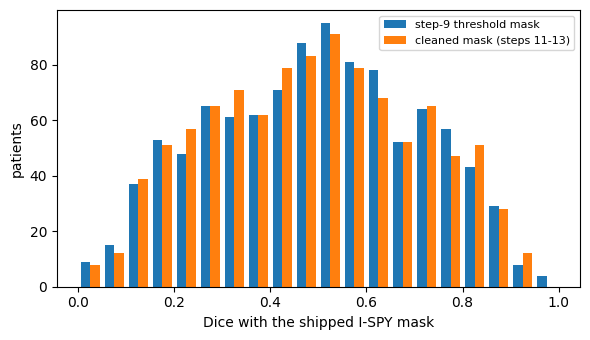

In [5]:
R2 = f"{OUT}/radiomics2"
cmd = [sys.executable, "-m", "src.vitonly.radiomics2", "--out", R2, "--jobs", str(JOBS), "--prefer", PREFER,
       "--cache-root", "/kaggle/input", "/kaggle/working"]
if not USE_N4: cmd.append("--no-n4")
if DEBUG: cmd += ["--limit", "40"]
say("1. radiomics 2.0 starts (pass 1: N4 + Nyul landmarks, pass 2: features; progress every 100 patients)")
run_cmd(cmd)
FEAT = pd.read_csv(f"{R2}/features.csv", dtype={"pid": str})
QC = pd.read_csv(f"{R2}/qc.csv", dtype={"pid": str})
blocks = {p: sum(c.startswith(p) for c in FEAT.columns) for p in ("kin_", "t9_", "tn_", "peri_", "hab_", "vol_")}
say(f"1. done: {len(FEAT)} patients, feature blocks {blocks}, N4 applied to {int(QC.qc_n4.sum())}/{len(QC)}")
q = QC.dropna(subset=["qc_dice_clean"])
if len(q):
    print("Dice of our tumour mask with the shipped I-SPY masks (cleaned rule vs step 9's raw threshold):")
    print(q.groupby("cohort")[["qc_dice_clean", "qc_dice_step9"]].agg(["mean", "median"]).round(3).to_string())
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist([q.qc_dice_step9, q.qc_dice_clean], bins=20, range=(0, 1), label=["step-9 threshold mask", "cleaned mask (steps 11-13)"])
    ax.set_xlabel("Dice with the shipped I-SPY mask"); ax.set_ylabel("patients"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/mask_dice.png", dpi=120); plt.show()

## 2. Frozen DINOv2 on every tumour slice (GPU, ~5-10 min)
Up to `MAX_SLICES` slices per patient, evenly spaced over the tumour; each slice keeps its tumour area (for the
area-weighted mean) and its position. The same embeddings also give step 10's choice (8 central slices, plain mean)
for a like-for-like comparison.

In [6]:
EMB_DIR = f"{OUT}/embeddings"
EMB = f"{EMB_DIR}/slices_{BACKBONE}_{VIT_NORM}.npz"
if RUN_VIT:
    cmd = [sys.executable, "-m", "src.vitonly.slice_embed", "--out", EMB_DIR, "--backbone", BACKBONE, "--norm", VIT_NORM,
           "--max-slices", str(MAX_SLICES), "--prefer", PREFER, "--cache-root", "/kaggle/input", "/kaggle/working"]
    if DEBUG: cmd += ["--limit", "40"]
    say("2. DINOv2 embeddings of every tumour slice start (progress every 100 patients)")
    run_cmd(cmd)
else:
    say("2. skipped (RUN_VIT = False): the ViT feature sets are left out")

[10:56:52 | 2.35 h elapsed, 8.65 h left] 2. DINOv2 embeddings of every tumour slice start (progress every 100 patients)

/usr/bin/python3 -m src.vitonly.slice_embed --out /kaggle/working/results/vaib/step11/embeddings --backbone dinov2_b --norm sub --max-slices 32 --prefer v2 --cache-root /kaggle/input /kaggle/working
[data] 1 of 1099 patients have no cache entry, dropped (first: ['Breast_MRI_577'])
[slice_embed 10:56:55 +0.0 min] 1275 patients (train + val) | caches ispy1: v1 uint8 builder 1, ispy2: v1 uint8 builder 1, duke: v1 uint8 builder 1 | dinov2_b, norm sub, crop tumor, 1 view(s), up to 32 slices

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 2703.70it/s]
[slice_embed 10:57:27 +0.5 min]   100/1275 patients, 0.2 min, eta 2.2 min
[slice_embed 10:57:36 +0.7 min]   200/1275 patients, 0.3 min, eta 1.8 min
[slice_embed 10:57:46 +0.8 min]   300/1275 patients, 0.5 min, eta 1.6 min
[slice_embed 10:57:58 +1.0 min]   400/1275 patients, 0.7 min, eta 1.5 min
[slice_embed 10:58:09 

## 3. Score every feature set (repeated nested CV)
Feature sets: `kin16` (step 9 best) -> `tumour_s9norm` -> `tumour_n4nyul` -> `tumour+peri` -> `radiomics2` (+ habitats)
-> `radiomics2+kin16`; `vit_mid8` (step 10 style) -> `vit_all`; `combined` (radiomics2 + kin16 + vit_all); and
`volume_only`. Each x subtype mode (`image`, `+subtype`, `per_subtype`) x ComBat (off / on).

In [7]:
SC = f"{OUT}/scores"
cmd = [sys.executable, "-m", "src.vitonly.step11", "--features", R2, "--out", SC, "--modes", *MODES,
       "--repeats", str(2 if DEBUG else REPEATS), "--jobs", str(JOBS)]
if RUN_VIT and os.path.exists(EMB): cmd += ["--embeddings", EMB]
if not COMBAT: cmd.append("--no-combat")
say("3. scoring starts (one line per configuration, then the paired comparisons)")
run_cmd(cmd)
RES = pd.read_csv(f"{SC}/results.csv")
CMPS = pd.read_csv(f"{SC}/comparisons.csv")
OOF = pd.read_csv(f"{SC}/oof_preds.csv", dtype={"pid": str})
VAL = pd.read_csv(f"{SC}/val_preds.csv", dtype={"pid": str})
RES["combat"] = RES.combat.astype(str).str.lower() == "true"
say(f"3. done: {len(RES)} rows in {SC}/results.csv")

[10:59:39 | 2.39 h elapsed, 8.61 h left] 3. scoring starts (one line per configuration, then the paired comparisons)

/usr/bin/python3 -m src.vitonly.step11 --features /kaggle/working/results/vaib/step11/radiomics2 --out /kaggle/working/results/vaib/step11/scores --modes image +subtype per_subtype --repeats 5 --jobs 4 --embeddings /kaggle/working/results/vaib/step11/embeddings/slices_dinov2_b_sub.npz
[step11 10:59:41 +0.0 min] step 1/4: load features | args {'features': '/kaggle/working/results/vaib/step11/radiomics2', 'embeddings': '/kaggle/working/results/vaib/step11/embeddings/slices_dinov2_b_sub.npz', 'out': '/kaggle/working/results/vaib/step11/scores', 'modes': ['image', '+subtype', 'per_subtype'], 'no_combat': False, 'batch': 'protocol', 'repeats': 5, 'folds': 5, 'pca_vit': 32, 'jobs': 4}
[step11 10:59:42 +0.0 min]   embeddings /kaggle/working/results/vaib/step11/embeddings/slices_dinov2_b_sub.npz: 1275 patients, 33753 slices
[step11 10:59:42 +0.0 min]   train 1098 | val 177 | fe

## 4. Summary: which setting is best, and did each fix help?

TOP 15 by CV AUC (rank by CV; OOF = all train patients; val = the 177-patient confirmation):
          set        mode  combat  n_features  cv_auc  cv_auc_sd  oof_auc  oof_within_subtype  oof_within_cohort  val_auc  val_ci_lo  val_ci_hi  val_within_subtype  oof_vs_lookup  oof_vs_lookup_p
      vit_all    +subtype   False         768   0.691      0.028    0.694               0.598              0.711    0.630      0.544      0.714               0.529          0.067            0.000
      vit_all    +subtype    True         768   0.687      0.032    0.689               0.589              0.711    0.631      0.540      0.711               0.524          0.062            0.000
  volume_only    +subtype    True           5   0.686      0.028    0.686               0.568              0.695    0.655      0.568      0.739               0.569          0.059            0.000
        kin16 per_subtype    True          16   0.684      0.033    0.687               0.579              0.694    0.647  

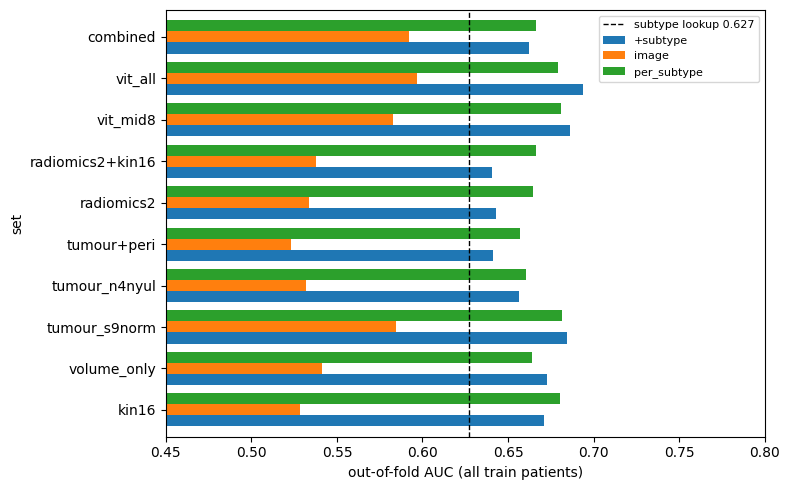


Did each fix help? b - a on the same patients (OOF = all train patients, val = 177):
                                         comparison  oof_auc_a  oof_auc_b  oof_diff  oof_p  val_auc_a  val_auc_b  val_diff  val_p
                   step-9 norm -> N4 + Nyul (image)      0.585      0.532    -0.053  0.000      0.572      0.559    -0.013  0.668
                          tumour -> + rings (image)      0.532      0.523    -0.009  0.570      0.559      0.570     0.011  0.752
                      + rings -> + habitats (image)      0.523      0.534     0.011  0.200      0.570      0.598     0.028  0.168
          kin16 (step 9 best) -> radiomics2 (image)      0.528      0.534     0.005  0.752      0.607      0.598    -0.009  0.836
            kin16 (step 9 best) -> combined (image)      0.528      0.592     0.064  0.000      0.607      0.587    -0.019  0.722
   ViT 8 mid slices (step 10) -> all slices (image)      0.583      0.597     0.014  0.060      0.541      0.547     0.007  0.638
    

In [8]:
cols = ["set", "mode", "combat", "n_features", "cv_auc", "cv_auc_sd", "oof_auc", "oof_within_subtype",
        "oof_within_cohort", "val_auc", "val_ci_lo", "val_ci_hi", "val_within_subtype", "oof_vs_lookup", "oof_vs_lookup_p"]
print("TOP 15 by CV AUC (rank by CV; OOF = all train patients; val = the 177-patient confirmation):")
print(RES[[c for c in cols if c in RES]].head(15).round(3).to_string(index=False))

order = ["kin16", "volume_only", "tumour_s9norm", "tumour_n4nyul", "tumour+peri", "radiomics2", "radiomics2+kin16",
         "vit_mid8", "vit_all", "combined"]
r = RES[(RES.set != "subtype_lookup") & (~RES.combat)]
piv = r.pivot_table(index="set", columns="mode", values="oof_auc").reindex([s for s in order if s in set(r.set)])
lk = float(RES.loc[RES.set == "subtype_lookup", "oof_auc"].iloc[0])
ax = piv.plot.barh(figsize=(8, 5), width=0.8)
ax.axvline(lk, color="k", ls="--", lw=1, label=f"subtype lookup {lk:.3f}")
ax.set_xlim(0.45, max(0.8, float(np.nanmax(piv.values)) + 0.02)); ax.set_xlabel("out-of-fold AUC (all train patients)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/oof_auc_by_set.png", dpi=120); plt.show()

print("\nDid each fix help? b - a on the same patients (OOF = all train patients, val = 177):")
print(CMPS[["comparison", "oof_auc_a", "oof_auc_b", "oof_diff", "oof_p", "val_auc_a", "val_auc_b", "val_diff", "val_p"]]
      .round(3).to_string(index=False))

ok = RES[RES.set != "subtype_lookup"]
key = lambda row: f"{row['set']}|{row['mode']}|{'combat' if row['combat'] else 'raw'}"
BEST = {f"best {m}": key(ok[ok["mode"] == m].iloc[0]) for m in MODES if (ok["mode"] == m).any()}
say("best per subtype mode (by CV): " + ", ".join(f"{k} = {v}" for k, v in BEST.items()))

# ---- the best configurations against the team's models on val (paired DeLong vs the subtype lookup) ----
def as_preds(frame, col):
    return frame[["pid", "cohort", "label"]].assign(prob=frame[col].values)
preds = {"B1 LR (clinical + size)": B1_VAL, "subtype lookup": as_preds(VAL, "subtype_lookup"),
         "F2 fusion v1 (old cache)": F2_V1}
preds.update({f"{STEP}: {name}": as_preds(VAL, col) for name, col in BEST.items() if col in VAL})
CMP = compare(preds, "subtype lookup")
print(CMP.round(3).to_string(index=False))
CMP.to_csv(f"{OUT}/comparison_vs_team.csv", index=False)
ours = {k: v for k, v in preds.items() if k.startswith(STEP)}
if ours:
    print("\nper subtype (val):"); print(subtype_wide(ours).to_string())
    print("\nper cohort (val):"); print(subtype_wide(ours, by="cohort").to_string())

## 5. Results file
`RESULTS_step11.md` = the scoring report (`scores/RESULTS.md`) + the comparison with the team's models.

In [9]:
from src.vitonly.rcv import md_table
txt = open(f"{SC}/RESULTS.md").read()
txt += "\n## Best configurations vs the team's models (val, paired DeLong vs the subtype lookup)\n\n" + md_table(CMP) + "\n"
open(f"{OUT}/RESULTS_step11.md", "w").write(txt)
say(f"wrote {OUT}/RESULTS_step11.md -- download it from the Output tab (or PUSH_RESULTS)")

[11:11:09 | 2.59 h elapsed, 8.41 h left] wrote /kaggle/working/results/vaib/step11/RESULTS_step11.md -- download it from the Output tab (or PUSH_RESULTS)


In [10]:
# ==== PUSH the small result files to the vaib branch (results/<PERSON>/...) ====
if PUSH_RESULTS and not _tok:
    print("PUSH_RESULTS needs the GITHUB_TOKEN secret; download results/ from the Output tab instead")
elif PUSH_RESULTS and not DEBUG:
    git("config", "user.name", f"Person {PERSON} (Kaggle)")
    git("config", "user.email", "kaggle@users.noreply.github.com")
    for attempt in range(3):
        git("fetch", "--quiet", "--depth", "1", "origin", f"+refs/heads/{GIT_TAG}:refs/remotes/origin/{GIT_TAG}")
        git("checkout", "--quiet", "-f", "-B", GIT_TAG, f"origin/{GIT_TAG}")
        shutil.copytree(f"/kaggle/working/results/{PERSON}", f"results/{PERSON}", dirs_exist_ok=True)
        git("add", f"results/{PERSON}")
        print(git("commit", "-m", f"results: {PERSON} {NOTEBOOK_NAME} ({GIT_TAG})"))
        try:
            git("push", "--quiet", "origin", GIT_TAG); print("pushed to", GIT_TAG); break
        except RuntimeError as e:
            print(f"push attempt {attempt + 1} failed:", e)
    else:
        print("NOT pushed: download results/ from the Output tab")